# 01 · Exploratory data analysis (M4)

What the cleaned corridor data looks like, and whether it can support each PRD target before any model is trained. Reads the M2/M3 outputs; changes nothing.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils import CONFIG, path
plt.rcParams["figure.figsize"] = (10, 4)
df = pd.read_csv(path("processed", f"flowcast_features_v{CONFIG['project']['version']}.csv"), parse_dates=["timestamp"])
real = df[df["is_imputed"] == 0]
print(f"{len(df):,} rows ({len(real):,} real readings, {int(df.is_imputed.sum()):,} rebuilt windows), {df.shape[1]} columns")

181,200 rows (176,701 real readings, 4,499 rebuilt windows), 78 columns


## 1. Target distributions

,traffic_volume,avg_speed,occupancy,travel_time
count,176701.00,176701.00,176701.00,176701.00
mean,431.45,42.10,31.26,3.57
std,283.56,11.39,19.74,2.53
min,41.00,6.70,3.00,0.80
25%,195.00,36.20,14.20,2.20
50%,362.00,44.90,27.10,3.12
75%,601.00,50.90,43.90,4.09
max,2090.00,64.80,100.00,29.91


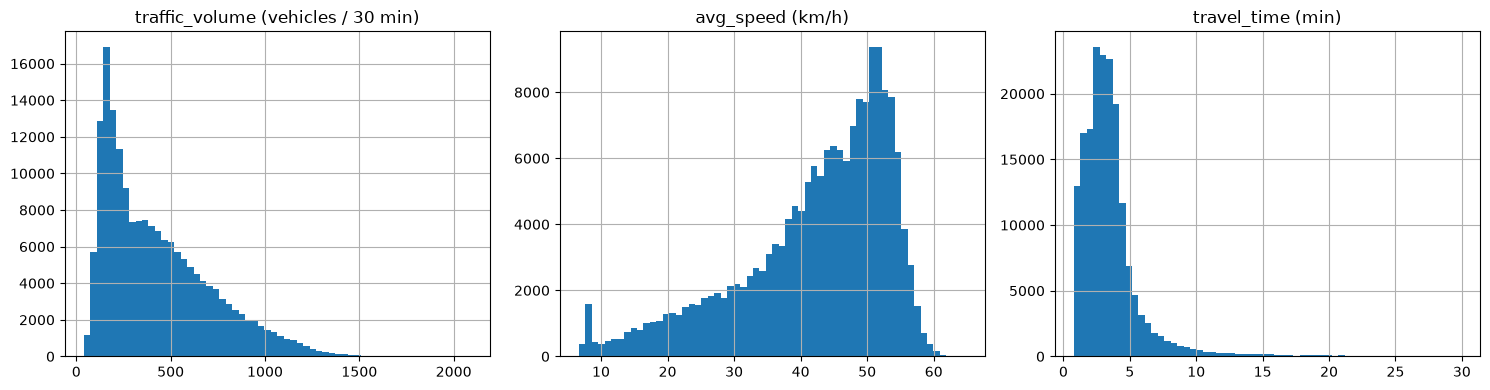

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
real["traffic_volume"].hist(bins=60, ax=ax[0]); ax[0].set_title("traffic_volume (vehicles / 30 min)")
real["avg_speed"].hist(bins=60, ax=ax[1]); ax[1].set_title("avg_speed (km/h)")
real["travel_time"].hist(bins=60, ax=ax[2]); ax[2].set_title("travel_time (min)")
plt.tight_layout(); plt.savefig(path("figures", "eda_distributions.png"), dpi=100)
real[["traffic_volume", "avg_speed", "occupancy", "travel_time"]].describe().round(2)

Travel time has a long right tail: a few heavily jammed windows take many times longer than normal. That tail is why percentage errors on travel time punish slow windows hardest.

## 2. Daily rhythm

weekday peaks: {8: 970.0, 9: 919.0}


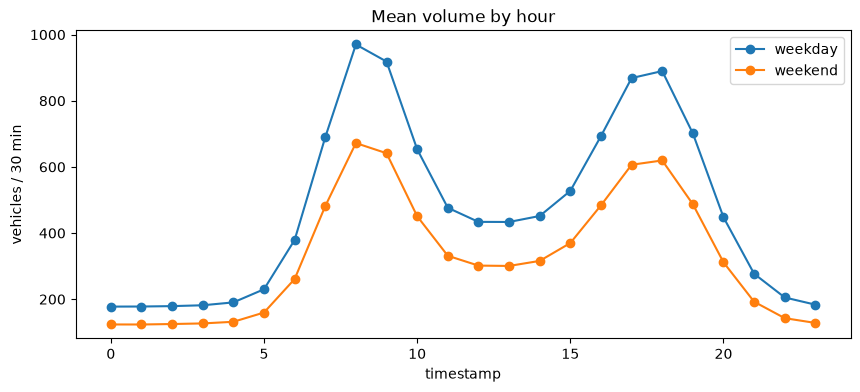

In [3]:
prof = real.groupby([real.timestamp.dt.hour, np.where(real.is_weekend == 1, "weekend", "weekday")])["traffic_volume"].mean().unstack()
prof.plot(marker="o", title="Mean volume by hour"); plt.ylabel("vehicles / 30 min")
plt.savefig(path("figures", "eda_hourly_pattern.png"), dpi=100)
print("weekday peaks:", prof["weekday"].nlargest(2).round(0).to_dict())

Two weekday rush hours, flatter weekends. A model that knows the hour and the day already has most of the signal, which is why time encodings and the same-time-yesterday lag matter so much.

## 3. Class balance of the classification targets

congestion_level
Free-flow    61.4
Moderate     23.8
Heavy         9.2
Severe        5.5

windows with an accident: 0.93%


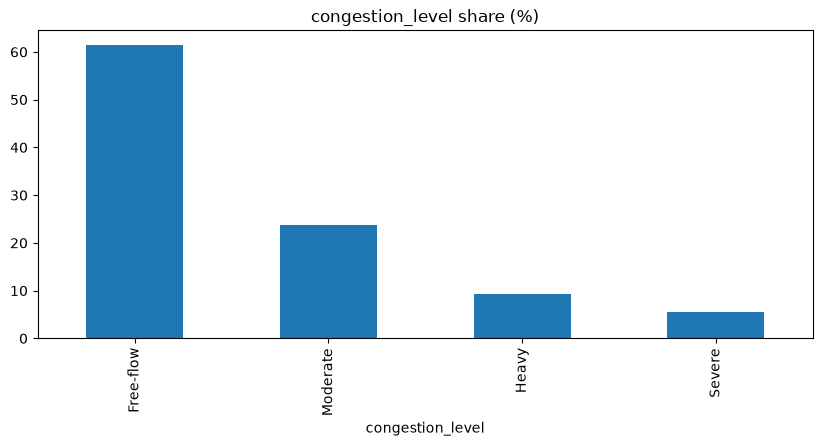

In [4]:
cong = real["congestion_level"].value_counts(normalize=True).reindex(CONFIG["cleaning"]["congestion_levels"]) * 100
acc = (real["accident_count"] > 0).mean() * 100
print(cong.round(1).to_string()); print(f"\nwindows with an accident: {acc:.2f}%")
cong.plot.bar(title="congestion_level share (%)"); plt.savefig(path("figures", "eda_congestion_balance.png"), dpi=100)

Severe is rare and accidents are rarer still. Plain accuracy would be meaningless on both, so the PRD scores congestion with macro-F1 and accidents with ROC-AUC, and the accident models use class weighting.

## 4. Correlations with next-window volume

avg_speed_lag1              -0.825
hour_cos                    -0.518
is_rain_lag1                -0.038
temperature_lag1             0.355
is_peak_period               0.712
traffic_volume_roll4_mean    0.801
traffic_volume_lag48         0.867
vc_ratio_lag1                0.882
traffic_volume_lag1          0.935
Name: traffic_volume, dtype: float64

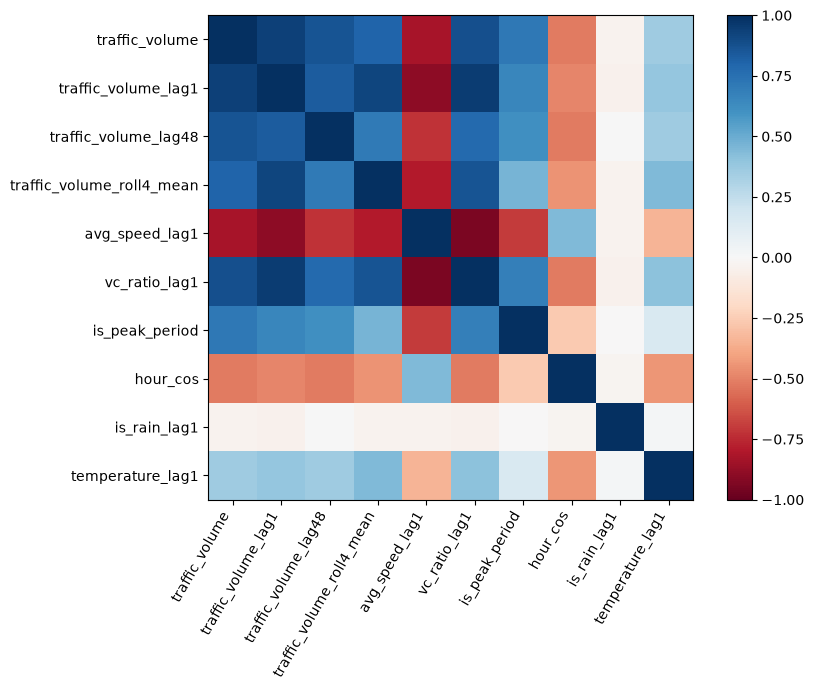

In [5]:
cols = ["traffic_volume", "traffic_volume_lag1", "traffic_volume_lag48", "traffic_volume_roll4_mean",
        "avg_speed_lag1", "vc_ratio_lag1", "is_peak_period", "hour_cos", "is_rain_lag1", "temperature_lag1"]
corr = real[cols].corr()
plt.figure(figsize=(9, 7)); plt.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=60, ha="right"); plt.yticks(range(len(cols)), cols); plt.colorbar()
plt.tight_layout(); plt.savefig(path("figures", "eda_correlations.png"), dpi=100)
corr["traffic_volume"].drop("traffic_volume").sort_values().round(3)

History is the strongest signal. Rain barely moves volume as a straight-line correlation; check speed instead (next cell). A weak correlation means 'no straight-line link overall', not 'no effect'.

## 5. Weather effect, peak hours only

In [6]:
peak = real[real.is_peak_period == 1]
peak.groupby("weather_condition")[["traffic_volume", "avg_speed"]].mean().round(1)

,traffic_volume,avg_speed
weather_condition,,
Clear,836.2,24.6
Cloudy,811.6,25.9
Fog,475.0,36.2
Overcast,822.7,25.3
Rain,676.5,28.4


## 6. What this means for modelling

- Volume and speed: strong daily and lag signal, so tree ensembles on lag features should do well.
- Congestion: imbalanced, so macro-F1 and per-class recall matter more than accuracy.
- Accidents: about 1 positive in 100, so class weighting, probability calibration and a chosen alert threshold are needed; even then the data may not carry enough signal for ROC-AUC 0.75.